# Rede neural em NumPy: reprodução do CS231n

Código do **slide 30**, retomado nos slides 31 a 34 de *Lecture 4: Neural Networks and Backpropagation*, de **Fei-Fei Li, Yunzhu Li e Ruohan Gao**, Stanford, 13/04/2023.

[Slides de origem](https://cs231n.stanford.edu/slides/2023/lecture_4.pdf) · [Repositório](https://github.com/mh131105/cs231n-rede-neural)

Execute as células na ordem, com **Restart Kernel and Run All**. O notebook gera os dados; não exige arquivos externos, GPU ou acesso à rede durante o treino. Consulte o README para instalar as dependências. A análise acompanha a entrega em um relatório PDF separado.

## 1. Ambiente

Semente: `0`. Dependências de referência: NumPy `2.3.5` e Matplotlib `3.10.7`. Bibliotecas e processadores distintos podem produzir diferenças de arredondamento.

In [1]:
import platform
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

print(f"Python {platform.python_version()}")
print(f"NumPy {np.__version__} | Matplotlib {matplotlib.__version__}")

Python 3.12.12
NumPy 2.3.5 | Matplotlib 3.10.7


## 2. Código original

A célula de treino preserva o trecho do slide, inclusive `N` maiúsculo e as 2.000 impressões. A linha `%%capture saida_original` guarda essas impressões para montar a tabela e o gráfico. Definimos a semente na célula anterior ao trecho; o slide não fixa uma semente.

In [2]:
np.random.seed(0)

In [3]:
%%capture saida_original
import numpy as np
from numpy.random import randn

N, D_in, H, D_out = 64, 1000, 100, 10
x, y = randn(N, D_in), randn(N, D_out)
w1, w2 = randn(D_in, H), randn(H, D_out)

for t in range(2000):
    h = 1 / (1 + np.exp(-x.dot(w1)))
    y_pred = h.dot(w2)
    loss = np.square(y_pred - y).sum()
    print(t, loss)

    grad_y_pred = 2.0 * (y_pred - y)
    grad_w2 = h.T.dot(grad_y_pred)
    grad_h = grad_y_pred.dot(w2.T)
    grad_w1 = x.T.dot(grad_h * h * (1 - h))

    w1 -= 1e-4 * grad_w1
    w2 -= 1e-4 * grad_w2

## 3. Resultados do treino

Cada impressão registra a perda **antes** da atualização daquela iteração. A avaliação após as 2.000 atualizações exige outro forward pass. Os valores da coluna “PDF de exemplo” vêm da seção 4 do material do colega e contêm arredondamentos.

In [4]:
registros = np.array([list(map(float, linha.split()))
                     for linha in saida_original.stdout.splitlines()])
assert registros.shape == (2000, 2)
np.testing.assert_array_equal(registros[:, 0], np.arange(2000))
perdas = registros[:, 1]
assert np.isfinite(perdas).all()

marcos = [0, 10, 100, 500, 1000, 1999]
valores_exemplo = [24636, 8926, 2383, 211, 41, 4.3]
tabela = ["| Iteração | PDF de exemplo (arred.) | Esta execução (SSE) |",
          "|---:|---:|---:|"]
for passo, exemplo in zip(marcos, valores_exemplo):
    tabela.append(f"| {passo} | {exemplo:g} | {perdas[passo]:.6f} |")
display(Markdown("\n".join(tabela)))

h_final = 1 / (1 + np.exp(-x.dot(w1)))
pred_final = h_final.dot(w2)
sse_final = np.square(pred_final - y).sum()
mse_treino = np.square(pred_final - y).mean()
print(f"Após 2000 atualizações: SSE = {sse_final:.6f}; MSE = {mse_treino:.8f}")

| Iteração | PDF de exemplo (arred.) | Esta execução (SSE) |
|---:|---:|---:|
| 0 | 24636 | 24635.893499 |
| 10 | 8926 | 8926.010224 |
| 100 | 2383 | 2383.155575 |
| 500 | 211 | 210.984308 |
| 1000 | 41 | 41.046079 |
| 1999 | 4.3 | 4.348503 |

Após 2000 atualizações: SSE = 4.340053; MSE = 0.00678133


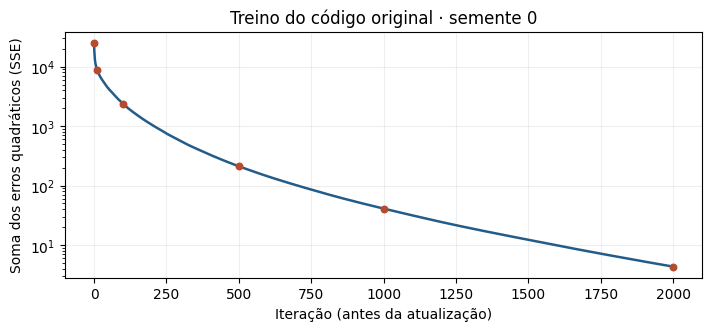

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.2), constrained_layout=True)
ax.semilogy(registros[:, 0], perdas, color="#245c89", linewidth=1.8)
ax.scatter(marcos, perdas[marcos], color="#b54c2f", s=22, zorder=3)
ax.set(xlabel="Iteração (antes da atualização)",
       ylabel="Soma dos erros quadráticos (SSE)", title="Treino do código original · semente 0")
ax.grid(alpha=0.2)
plt.show()

## 4. Verificações

Recriamos os valores iniciais com um gerador separado. Assim, os diagnósticos preservam os pesos finais do treino. Conferimos dimensões, número de parâmetros e gradientes de 8 coordenadas de cada matriz inicial por diferenças centrais (`epsilon = 1e-5`). Essa amostragem verifica parte dos 101.000 gradientes.

In [6]:
rng_inicial = np.random.RandomState(0)
x_inicial = rng_inicial.randn(N, D_in)
y_inicial = rng_inicial.randn(N, D_out)
w1_inicial = rng_inicial.randn(D_in, H)
w2_inicial = rng_inicial.randn(H, D_out)
np.testing.assert_array_equal(x, x_inicial)
np.testing.assert_array_equal(y, y_inicial)
assert x.shape == (64, 1000) and y.shape == (64, 10)
assert w1.shape == (1000, 100) and w2.shape == (100, 10)
assert w1.size + w2.size == 101000
assert np.isfinite(w1).all() and np.isfinite(w2).all()
print(f"Arquitetura: {D_in} → {H} → {D_out}; {w1.size + w2.size:,} pesos; sem vieses.")

Arquitetura: 1000 → 100 → 10; 101,000 pesos; sem vieses.


In [7]:
def perda_e_gradientes(a, b):
    oculta = 1 / (1 + np.exp(-x.dot(a)))
    erro = oculta.dot(b) - y
    grad_saida = 2.0 * erro
    grad_b = oculta.T.dot(grad_saida)
    grad_a = x.T.dot(grad_saida.dot(b.T) * oculta * (1 - oculta))
    return np.square(erro).sum(), grad_a, grad_b


_, grad_a, grad_b = perda_e_gradientes(w1_inicial, w2_inicial)
rng_check = np.random.RandomState(7)
epsilon = 1e-5
erros_gradiente = {}
for nome, matriz, grad in [("w1", w1_inicial, grad_a), ("w2", w2_inicial, grad_b)]:
    numericos, analiticos = [], []
    for posicao in rng_check.choice(matriz.size, size=8, replace=False):
        indice = np.unravel_index(posicao, matriz.shape)
        valor = matriz[indice]
        try:
            matriz[indice] = valor + epsilon
            mais = perda_e_gradientes(w1_inicial, w2_inicial)[0]
            matriz[indice] = valor - epsilon
            menos = perda_e_gradientes(w1_inicial, w2_inicial)[0]
        finally:
            matriz[indice] = valor
        numericos.append((mais - menos) / (2 * epsilon))
        analiticos.append(grad[indice])
    numericos, analiticos = np.array(numericos), np.array(analiticos)
    np.testing.assert_allclose(numericos, analiticos, rtol=1e-4, atol=1e-5)
    erro_relativo = np.linalg.norm(numericos - analiticos) / max(
        1e-12, np.linalg.norm(numericos) + np.linalg.norm(analiticos))
    erros_gradiente[nome] = erro_relativo
    print(f"{nome}: 8 coordenadas conferidas; erro relativo por norma = {erro_relativo:.2e}")

w1: 8 coordenadas conferidas; erro relativo por norma = 1.66e-09
w2: 8 coordenadas conferidas; erro relativo por norma = 5.21e-10


## 5. Diagnósticos para o relatório

Medimos a saturação inicial pelo critério `h < 0.01` ou `h > 0.99`. Depois avaliamos os pesos finais em 4.096 pares novos de entradas e alvos independentes, com semente `1`. Comparamos o MSE com o preditor que retorna zero. Esse teste complementa o trecho do slide; não participa do treino.

In [8]:
z_inicial = x.dot(w1_inicial)
h_inicial = 1 / (1 + np.exp(-z_inicial))
saturacao = ((h_inicial < 0.01) | (h_inicial > 0.99)).mean()

rng_teste = np.random.RandomState(1)
x_teste = rng_teste.randn(4096, D_in)
y_teste = rng_teste.randn(4096, D_out)
h_teste = 1 / (1 + np.exp(-x_teste.dot(w1)))
pred_teste = h_teste.dot(w2)
mse_teste = np.square(pred_teste - y_teste).mean()
mse_zero = np.square(y_teste).mean()
assert np.isfinite([sse_final, mse_treino, mse_teste, mse_zero]).all()
np.testing.assert_allclose(sse_final, mse_treino * N * D_out)

print(f"Desvio padrão de x @ w1 inicial: {z_inicial.std():.4f}")
print(f"Ativações iniciais saturadas: {100 * saturacao:.5f}%")
print(f"MSE treino: {mse_treino:.8f}")
print(f"MSE teste: {mse_teste:.6f}")
print(f"MSE teste, preditor zero: {mse_zero:.6f}")
print(f"SSE / MSE = N × D_out = {N * D_out}")

Desvio padrão de x @ w1 inicial: 31.1720
Ativações iniciais saturadas: 87.90625%
MSE treino: 0.00678133
MSE teste: 17.899127
MSE teste, preditor zero: 1.004008
SSE / MSE = N × D_out = 640


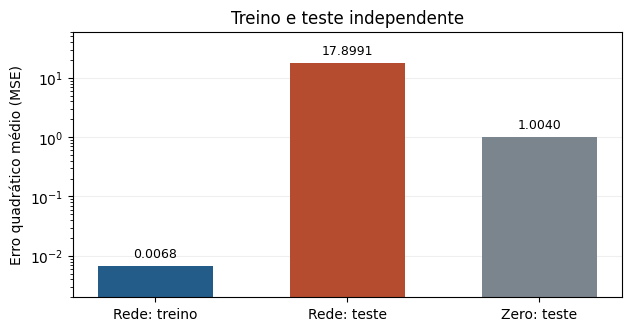

In [9]:
fig, ax = plt.subplots(figsize=(6.2, 3.2), constrained_layout=True)
nomes = ["Rede: treino", "Rede: teste", "Zero: teste"]
valores = [mse_treino, mse_teste, mse_zero]
barras = ax.bar(nomes, valores, color=["#245c89", "#b54c2f", "#7b858d"], width=0.6)
ax.set(yscale="log", ylabel="Erro quadrático médio (MSE)",
       title="Treino e teste independente")
ax.bar_label(barras, labels=[f"{valor:.4f}" for valor in valores], padding=4, fontsize=9)
ax.set_ylim(0.002, 60)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.show()

Os resultados ficam salvos nas saídas do notebook. Para repetir o experimento, reinicie o kernel e execute as células na ordem. O PDF de análise usa essas medições e a mesma versão do código do slide 30.